# AST325

### Python Zoom Session. October 23, 2023.

###In this notebook we will go over peak finding in Python!

In [1]:
#import everything
%matplotlib inline
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.gridspec as gridspec
import matplotlib.ticker as ticker
import numpy as np
import scipy as sp

Let's load a dataset of a xenon spectrum. (NIST Atomic Spectra Database, https://www.atomtrace.com/elements-database/element/54)

In [2]:
wavelength, intensity = np.loadtxt('54_NIST.asc', unpack = True)

In [3]:
plt.rcParams["figure.figsize"] = (7,4)
plt.rcParams['font.size'] = 16
plt.rcParams['xtick.labelsize'] = 12
plt.rcParams['ytick.labelsize'] = 12

Let's take a look at the data.

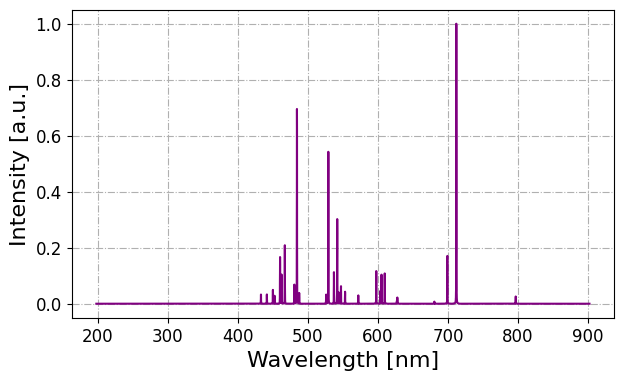

In [4]:
plt.figure()

plt.plot(wavelength, intensity, color = 'purple')

plt.xlabel('Wavelength [nm]')
plt.ylabel('Intensity [a.u.]')

plt.grid(ls = '-.')
plt.show()

###Now let's use scipy.find_peaks to find the peak locations. We have multiple parameters we can use to specify how many/what types of peaks we want. Play around with different settings to compare them!

* **Height:** Required height of peaks. Either a number, None, an array matching x or a 2-element sequence of the former. The first element is always interpreted as the minimal and the second, if supplied, as the maximal required height.

* **Width:** Required width of peaks in samples. Either a number, None, an array matching x or a 2-element sequence of the former. The first element is always interpreted as the minimal and the second, if supplied, as the maximal required width.

* **Distance:** Required minimal horizontal distance (>= 1) in samples between neighbouring peaks. Smaller peaks are removed first until the condition is fulfilled for all remaining peaks.

* **Threshold:** Required threshold of peaks, the vertical distance to its neighboring samples. Either a number, None, an array matching x or a 2-element sequence of the former. The first element is always interpreted as the minimal and the second, if supplied, as the maximal required threshold.
#

* **Prominence:** Required prominence of peaks. Either a number, None, an array matching x or a 2-element sequence of the former. The first element is always interpreted as the minimal and the second, if supplied, as the maximal required prominence.



In [5]:

min_height = 0.03 * np.max(intensity)
peaks = sp.signal.find_peaks(intensity, height=min_height)[0]

num_peaks = len(peaks)

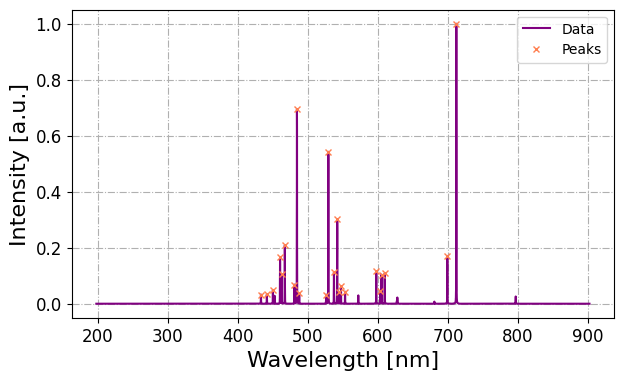

In [6]:
plt.figure()

plt.plot(wavelength, intensity, color = 'purple', label = 'Data')
plt.plot(wavelength[peaks], intensity[peaks], color = 'coral', ls = '',
         marker = 'x',  ms = 5, label = 'Peaks')

plt.xlabel('Wavelength [nm]')
plt.ylabel('Intensity [a.u.]')

plt.legend(loc = 'best', fontsize = 10)
plt.grid(ls = '-.')
plt.show()

####We can now use these peaks to find the centroids which can be thought of as the "center of mass" or weighted mean of the peaks. The peaks may not be the actual peak value as we are limited by our measurments which is why we we can't just use the peak value!

Recall from class,

$x_{\text{cent}} = \frac{∑x_iI_i}{∑I_i}$,

where $x_{\text{cent}}$ is the centroid, $x_i$ are the x-values, and $I_i$ are the intensity values. Also note that this assumes that the background is distributed around 0!

In [7]:
def centroid(x, I):
  '''
  Returns the centroid value for a given set of x- and intensity values.

  Input: x: x values, I: intensity values
  Output: centroid value
  '''

  return np.sum(x*I)/np.sum(I)

###Let's look at what value we should use for our centroid ranges around the peaks.

---



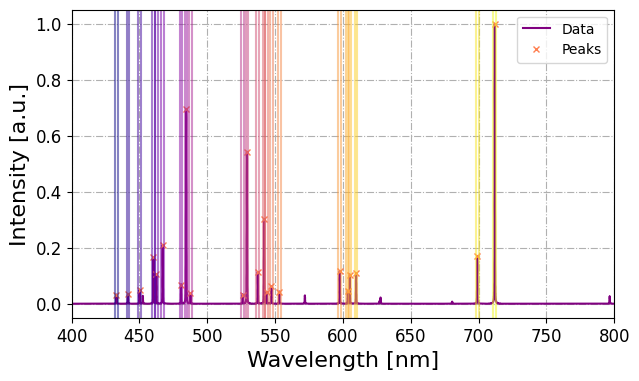

In [8]:
plt.figure()

range_val = 50

colours = cm.plasma(np.linspace(0, 1, num_peaks))

plt.plot(wavelength, intensity, color = 'purple', label = 'Data')
plt.plot(wavelength[peaks], intensity[peaks], color = 'coral', ls = '',
         marker = 'x',  ms = 5, label = 'Peaks')

[plt.axvline(wavelength[peaks[i]-range_val], color = colours[i], alpha = 0.5)
for i in range(len(peaks))]

[plt.axvline(wavelength[peaks[i]+range_val], color = colours[i], alpha = 0.5)
for i in range(len(peaks))]

plt.xlabel('Wavelength [nm]')
plt.ylabel('Intensity [a.u.]')

plt.legend(loc = 'best', fontsize = 10)
plt.grid(ls = '-.')
plt.xlim((400, 800))
plt.show()

Let's zoom in to confirm these ranges.

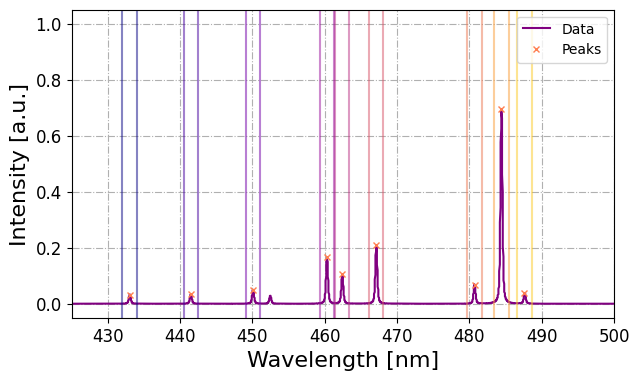

In [9]:
plt.figure()

colours_t = cm.plasma(np.linspace(0, 1, 10))

plt.plot(wavelength, intensity, color = 'purple', label = 'Data')
plt.plot(wavelength[peaks], intensity[peaks], color = 'coral', ls = '',
         marker = 'x',  ms = 5, label = 'Peaks')

[plt.axvline(wavelength[peaks[i]-range_val], color = colours_t[i], alpha = 0.5)
for i in range(len(peaks[:10]))]

[plt.axvline(wavelength[peaks[i]+range_val], color = colours_t[i], alpha = 0.5)
for i in range(len(peaks[:10]))]

plt.xlabel('Wavelength [nm]')
plt.ylabel('Intensity [a.u.]')

plt.legend(loc = 'best', fontsize = 10)
plt.grid(ls = '-.')
plt.xlim((425, 500))
plt.show()

In [10]:
centroids = [centroid(wavelength[peaks[i]-range_val:peaks[i]+range_val], intensity[peaks[i]-range_val:peaks[i]+range_val]) for i in range(len(peaks))]

Let's plot the centroids.

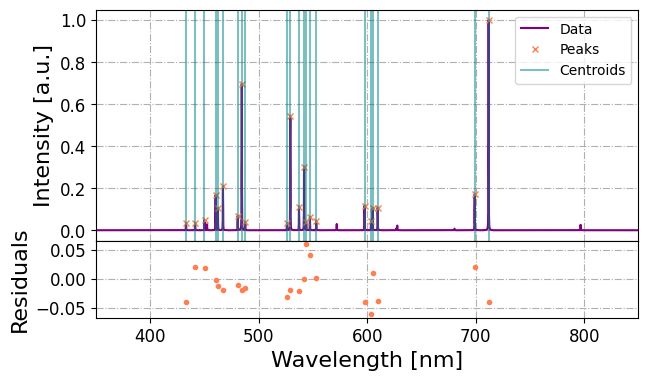

In [11]:
fig = plt.figure()

gs = gridspec.GridSpec(2, 1, height_ratios=[3, 1], hspace = 0.0)
ax0 = plt.subplot(gs[0])
ax1 = plt.subplot(gs[1], sharex = ax0)

ax0.plot(wavelength, intensity, color = 'purple', label = 'Data')
ax0.plot(wavelength[peaks], intensity[peaks], color = 'coral', ls = '', marker = 'x',
         ms = 5, label = 'Peaks')

[ax0.axvline(c, color = 'teal', alpha = 0.5, label = 'Centroids') if c == centroids[0]
 else ax0.axvline(c, color = 'teal', alpha = 0.5) for c in centroids]

ax1.plot(wavelength[peaks], wavelength[peaks] - centroids, ls = '', marker = '.', color = 'coral')

ax1.set_xlabel('Wavelength [nm]')
ax0.set_ylabel('Intensity [a.u.]')
ax1.set_ylabel('Residuals')

plt.setp(ax0.get_xticklabels(), visible = False)

ax0.legend(loc = 'best', fontsize = 10)
ax0.grid(ls = '-.')
ax1.grid(ls = '-.')
plt.xlim((350, 850))
plt.show()

Let's zoom in to check!

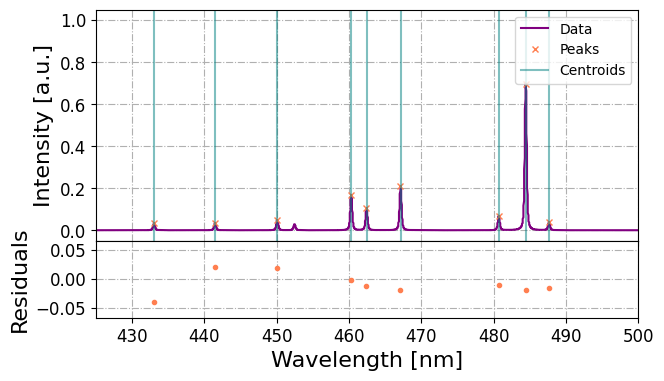

In [12]:
fig = plt.figure()

gs = gridspec.GridSpec(2, 1, height_ratios=[3, 1], hspace = 0.0)
ax0 = plt.subplot(gs[0])
ax1 = plt.subplot(gs[1], sharex = ax0)

ax0.plot(wavelength, intensity, color = 'purple', label = 'Data')
ax0.plot(wavelength[peaks], intensity[peaks], color = 'coral', ls = '', marker = 'x',
         ms = 5, label = 'Peaks')

[ax0.axvline(c, color = 'teal', alpha = 0.5, label = 'Centroids') if c == centroids[0]
 else ax0.axvline(c, color = 'teal', alpha = 0.5) for c in centroids]

ax1.plot(wavelength[peaks], wavelength[peaks] - centroids, ls = '', marker = '.', color = 'coral')

ax1.set_xlabel('Wavelength [nm]')
ax0.set_ylabel('Intensity [a.u.]')
ax1.set_ylabel('Residuals')

plt.setp(ax0.get_xticklabels(), visible = False)

ax0.legend(loc = 'best', fontsize = 10)
ax0.grid(ls = '-.')
ax1.grid(ls = '-.')
plt.xlim(425, 500)
plt.show()

###Now let's try doing this for a 2D source.



In [13]:
!pip install photutils

  Obtaining dependency information for photutils from https://files.pythonhosted.org/packages/57/ae/027bd894ca88dc26139ab828cc59180631d1b644e3b4088c2e4e78847ef9/photutils-1.9.0-cp311-cp311-macosx_11_0_arm64.whl.metadata
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 650.3/650.3 kB 29.0 MB/s eta 0:00:00

[notice] A new release of pip is available: 23.2.1 -> 23.3
[notice] To update, run: python3.11 -m pip install --upgrade pip


In [14]:
import photutils as putils
from photutils.datasets import make_4gaussians_image

###Now let's try doing this with the photutils library.

First let's do the center of mass estimate version as we did before.

In [15]:
#load dataset

data = make_4gaussians_image()[43:79, 76:104]

Let's the x- and y-corrdinates for the maximum values.

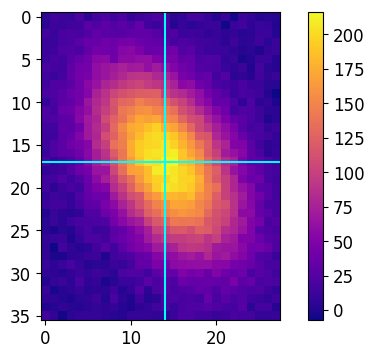

In [16]:
plt.figure()

plt.imshow(data, cmap = cm.plasma)

y_ind, x_ind = np.where(data == np.max(data))

plt.axvline(x_ind, color = 'cyan')
plt.axhline(y_ind, color = 'cyan')

plt.colorbar()
plt.show()

In [17]:
#selecting the data along the cyan lines above
x_cutout = data[y_ind, :][0]
y_cutout = data[:, x_ind].T

#Note that we know the background is 0 for this image from the colourbar above
x_centroid = centroid(np.arange(0, np.shape(data)[1]), x_cutout)

y_centroid = centroid(np.arange(0, np.shape(data)[0]), y_cutout)

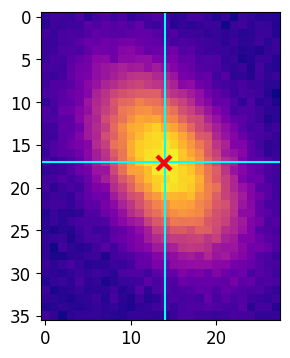

In [18]:
plt.figure()

plt.imshow(data, cmap = cm.plasma)

y_ind, x_ind = np.where(data == np.max(data))

plt.plot(x_centroid, y_centroid, color = 'red', ls = '', marker = 'x', mew = 3,
         ms = 10, zorder = 10)

plt.axvline(x_ind, color = 'cyan')
plt.axhline(y_ind, color = 'cyan')

plt.show()

Now let's use the photutils center of mass function.

In [19]:
x_com, y_com = putils.centroids.centroid_com(data)

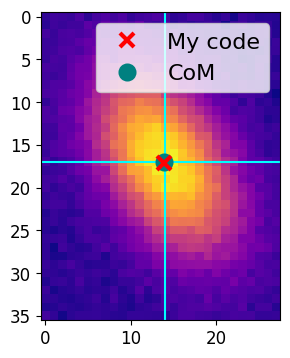

In [20]:
plt.figure()

plt.imshow(data, cmap = cm.plasma)

y_ind, x_ind = np.where(data == np.max(data))

plt.plot(x_centroid, y_centroid, color = 'red', ls = '', marker = 'x', mew = 3,
         ms = 10, zorder = 10, label = 'My code')

plt.plot(x_com, y_com, color = 'teal', ls = '', marker = 'o', mew = 3,
         ms = 10, zorder = 8, label  = 'CoM')

plt.axvline(x_ind, color = 'cyan')
plt.axhline(y_ind, color = 'cyan')

plt.legend(loc = 'best')
plt.show()

Now let's use the photutils Gaussian function that fits 1D Gaussians to the x- and y- marginal distributions.

In [21]:
x_gauss1d, y_gauss1d = putils.centroids.centroid_1dg(data)

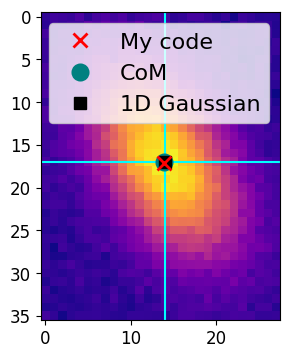

In [22]:
plt.figure()

plt.imshow(data, cmap = cm.plasma)

y_ind, x_ind = np.where(data == np.max(data))

plt.plot(x_centroid, y_centroid, color = 'red', ls = '', marker = 'x', mew = 2,
         ms = 10, zorder = 10, label = 'My code')

plt.plot(x_com, y_com, color = 'teal', ls = '', marker = 'o', mew = 3,
         ms = 10, zorder = 8, label  = 'CoM')

plt.plot(x_gauss1d, y_gauss1d, color = 'black', ls = '', marker = 's',
         ms = 8, zorder = 9, label  = '1D Gaussian')

plt.axvline(x_ind, color = 'cyan')
plt.axhline(y_ind, color = 'cyan')

plt.legend(loc = 'best')
plt.show()

Now let's use the photutils Gaussian function that fits 2D Gaussian to the image.

In [23]:
x_gauss2d, y_gauss2d = putils.centroids.centroid_2dg(data)

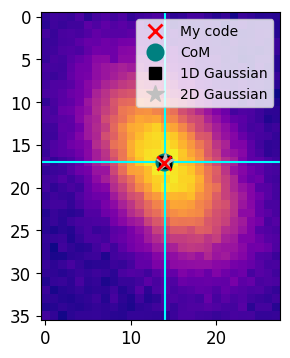

In [24]:
plt.figure()

plt.imshow(data, cmap = cm.plasma)

y_ind, x_ind = np.where(data == np.max(data))

plt.plot(x_centroid, y_centroid, color = 'red', ls = '', marker = 'x', mew = 2,
         ms = 10, zorder = 11, label = 'My code')

plt.plot(x_com, y_com, color = 'teal', ls = '', marker = 'o', mew = 3,
         ms = 10, zorder = 8, label  = 'CoM')

plt.plot(x_gauss1d, y_gauss1d, color = 'black', ls = '', marker = 's',
         ms = 8, zorder = 9, label  = '1D Gaussian')

plt.plot(x_gauss2d, y_gauss2d, color = 'silver', ls = '', marker = '*',
         ms = 13, zorder = 10, label  = '2D Gaussian')

plt.axvline(x_ind, color = 'cyan')
plt.axhline(y_ind, color = 'cyan')

plt.legend(loc = 'best', fontsize = 10)
plt.show()